# Customer360 AI: Predicting E-Commerce Customer Dissatisfaction
## Task 2: Data Cleaning, Integration, Feature Engineering, and Exploratory Data Analysis (EDA)
**Course:** COM-702 Applied Data Science  
**Dataset:** Brazilian E-Commerce Public Dataset by Olist (9 Relational CSVs)  
**Author:** CSE Data Science Research Team  

---

### Notebook Overview
This notebook presents the complete, reproducible data engineering and exploratory data analysis pipeline for the Customer360 AI project:
1. **Data Quality Assessment**: Structural inspection of all 9 relational tables, missingness patterns, and integrity validation.
2. **Review Handling & Corpus Preservation**: Deterministic tie-breaking for order-level ML while preserving all 99,224 original review texts for NLP diagnostics.
3. **Relational Integration & Aggregation**: Aggregating line items, products, and payments to the unique `order_id` grain prior to 1-to-1 merging (preventing Cartesian explosion).
4. **Target Formulation & Post-Fulfilment Timing**: Ground-truth dissatisfaction defined as Review Score $\in \{1, 2\}$ vs Satisfied $\in \{4, 5\}$, cleanly excluding neutral Score 3.
5. **Feature Engineering**: Deriving operational delivery metrics, financial friction ratios, physical item properties, and payment structures.
6. **Exploratory Data Analysis**: 6 publication-standard visual analyses revealing key empirical drivers of customer friction.


In [ ]:
# Imports & Configuration
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

RAW_DIR = os.path.join("..", "data", "raw")
PROCESSED_DIR = os.path.join("..", "data", "processed")
FIGURES_DIR = os.path.join("..", "outputs", "figures")
TABLES_DIR = os.path.join("..", "outputs", "tables")


## 1. Load Raw Datasets & Data Quality Audit
We load all nine CSV files from `data/raw/` and inspect primary keys, dimensions, and anomalies.


In [ ]:
# Load the 9 Olist tables
customers = pd.read_csv(os.path.join(RAW_DIR, 'olist_customers_dataset.csv'))
orders = pd.read_csv(os.path.join(RAW_DIR, 'olist_orders_dataset.csv'))
items = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_items_dataset.csv'))
payments = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_payments_dataset.csv'))
reviews = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_reviews_dataset.csv'))
products = pd.read_csv(os.path.join(RAW_DIR, 'olist_products_dataset.csv'))
sellers = pd.read_csv(os.path.join(RAW_DIR, 'olist_sellers_dataset.csv'))
geolocation = pd.read_csv(os.path.join(RAW_DIR, 'olist_geolocation_dataset.csv'))
translation = pd.read_csv(os.path.join(RAW_DIR, 'product_category_name_translation.csv'))

print(f"Customers:    {customers.shape}")
print(f"Orders:       {orders.shape}")
print(f"Order Items:  {items.shape}")
print(f"Payments:     {payments.shape}")
print(f"Reviews:      {reviews.shape}")
print(f"Products:     {products.shape}")
print(f"Sellers:      {sellers.shape}")
print(f"Geolocation:  {geolocation.shape}")
print(f"Translation:  {translation.shape}")


Customers:    (99441, 5)
Orders:       (99441, 8)
Order Items:  (112650, 7)
Payments:     (103886, 5)
Reviews:      (99224, 7)
Products:     (32951, 9)
Sellers:      (3095, 4)
Geolocation:  (1000163, 5)
Translation:  (71, 2)


## 2. Data Quality & Cleaning Decisions
We review the structured data quality audit table generated during pipeline execution.


In [ ]:
# Display Data Quality Report
dq_df = pd.read_csv(os.path.join(TABLES_DIR, 'data_quality_report.csv'))
display(dq_df)


,Dataset,Total Records,Primary Key,Missing Values,Key Anomalies Detected,Cleaning / Preprocessing Decision
0,olist_customers_dataset,99441,customer_id (Unique: 100%),0,"None. 3,345 repeat customer purchases identifi...",Preserve all rows. Feature engineered is_repea...
1,olist_orders_dataset,99441,order_id (Unique: 100%),4908,2965 orders missing customer delivery date (mo...,Convert timestamps to datetime. Filter deliver...
2,olist_order_items_dataset,112650,"(order_id, order_item_id) (Composite PK: 100%)",0,"0 negative prices, 0 negative freight values. ...","Aggregate to order_id grain: item count, total..."
3,olist_order_payments_dataset,103886,"(order_id, payment_sequential) (Composite PK: ...",0,9 orders with payment_value == 0 (voucher offs...,Aggregate to order_id grain: total payment val...
4,olist_order_reviews_dataset,99224,review_id (814 duplicate review_ids; 551 order...,145903,Review score range 1-5 strictly valid. 58.7% c...,"Preserve all 99,224 reviews for NLP in custome..."
5,olist_products_dataset,32951,product_id (Unique: 100%),2448,610 missing categories; 2 missing weights/dime...,Impute missing weights with category median. M...
6,olist_sellers_dataset,3095,seller_id (Unique: 100%),0,"None. 3,095 sellers across 23 Brazilian states...",Join via items to identify seller state and de...
7,product_category_name_translation,71,product_category_name,0,"2 categories in products ('pc_gamer', 'portate...",Supplement translation dictionary manually so ...


## 3. Review Deduplication & Corpus Preservation
- **Preservation**: All 99,224 original review records are preserved in `data/processed/customer360_reviews_nlp.csv` for Question 2 NLP analysis.
- **Order-Level ML Selection**: For the 551 orders with multiple reviews, we apply a deterministic tie-break: latest `review_answer_timestamp` $\rightarrow$ latest `review_creation_date` $\rightarrow$ highest `review_id`.


In [ ]:
# Review deduplication verification
reviews['answer_dt'] = pd.to_datetime(reviews['review_answer_timestamp'], errors='coerce')
reviews['creation_dt'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')

sorted_rev = reviews.sort_values(by=['answer_dt', 'creation_dt', 'review_id'], ascending=[False, False, False])
rev_order_level = sorted_rev.drop_duplicates(subset=['order_id'], keep='first')

print(f"Total reviews: {len(reviews):,}")
print(f"Unique orders with reviews: {rev_order_level['order_id'].nunique():,}")
print(f"Multi-review orders resolved: {reviews['order_id'].duplicated().sum():,}")


Total reviews: 99,224
Unique orders with reviews: 98,673
Multi-review orders resolved: 551


## 4. Relational Integration & Feature Engineering
We aggregate `order_items` and `order_payments` to the unique `order_id` grain, derive delivery SLA metrics from `orders`, and merge with 1-to-1 validation.


In [ ]:
# Inspect the final processed order-level dataset
cohort = pd.read_csv(os.path.join(PROCESSED_DIR, 'customer360_order_level.csv'))
print(f"Delivered Cohort Shape: {cohort.shape}")
print(f"Columns: {list(cohort.columns)[:10]} ... ({len(cohort.columns)} total columns)")

print(f"\nBinary Sample Distribution (Excluding Score 3):")
bin_cohort = cohort[cohort['is_binary_sample'] == 1]
print(bin_cohort['dissatisfied'].value_counts(normalize=True).round(4) * 100)


Delivered Cohort Shape: (95824, 51)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_duration_days', 'estimated_delivery_duration_days'] ... (51 total columns)

Binary Sample Distribution (Excluding Score 3):
dissatisfied
0    86.04
1    13.96
Name: proportion, dtype: float64


## 5. Statistical Feature Summary Table
The table below documents descriptive statistics and Pearson linear correlation with customer dissatisfaction ($Y=1$).


In [ ]:
# Feature summary
fs_df = pd.read_csv(os.path.join(TABLES_DIR, 'feature_summary.csv'))
display(fs_df)


,Feature Name,Data Type,Non-Null Count,Missing %,Mean,Std Dev,Min,Median,Max,Corr with Dissatisfaction
0,delivery_duration_days,float64,87908,0.00,12.36,9.40,0.53,10.11,208.35,0.3363
1,estimated_delivery_duration_days,float64,87908,0.00,23.68,8.76,2.01,23.20,149.59,0.0443
2,delivery_delay_days,float64,87908,0.00,-11.32,10.08,-146.02,-12.06,188.98,0.2750
3,is_delayed,int64,87908,0.00,0.08,0.27,0.00,0.00,1.00,0.3927
4,carrier_duration_days,float64,87907,0.00,9.17,8.61,-16.10,7.06,205.19,0.3029
5,approval_duration_days,float64,87895,0.01,0.43,0.85,0.00,0.01,30.77,0.0138
6,item_count,float64,87908,0.00,1.14,0.53,1.00,1.00,21.00,0.1344
7,total_price,float64,87908,0.00,137.64,211.01,0.85,86.90,13440.00,0.0425
8,total_freight,float64,87908,0.00,22.69,21.45,0.00,17.14,1794.96,0.0942
9,total_order_value,float64,87908,0.00,160.33,220.63,9.59,105.28,13664.08,0.0498


## 6. Publication-Quality Visual Exploratory Data Analysis
Below are the six diagnostic charts examining the operational, category, financial, temporal, and payment determinants of dissatisfaction.


### EDA 1: Review Score Distribution & Target Demarcation
Demarcates Dissatisfied ($1\star, 2\star$), Neutral ($3\star$), and Satisfied ($4\star, 5\star$).


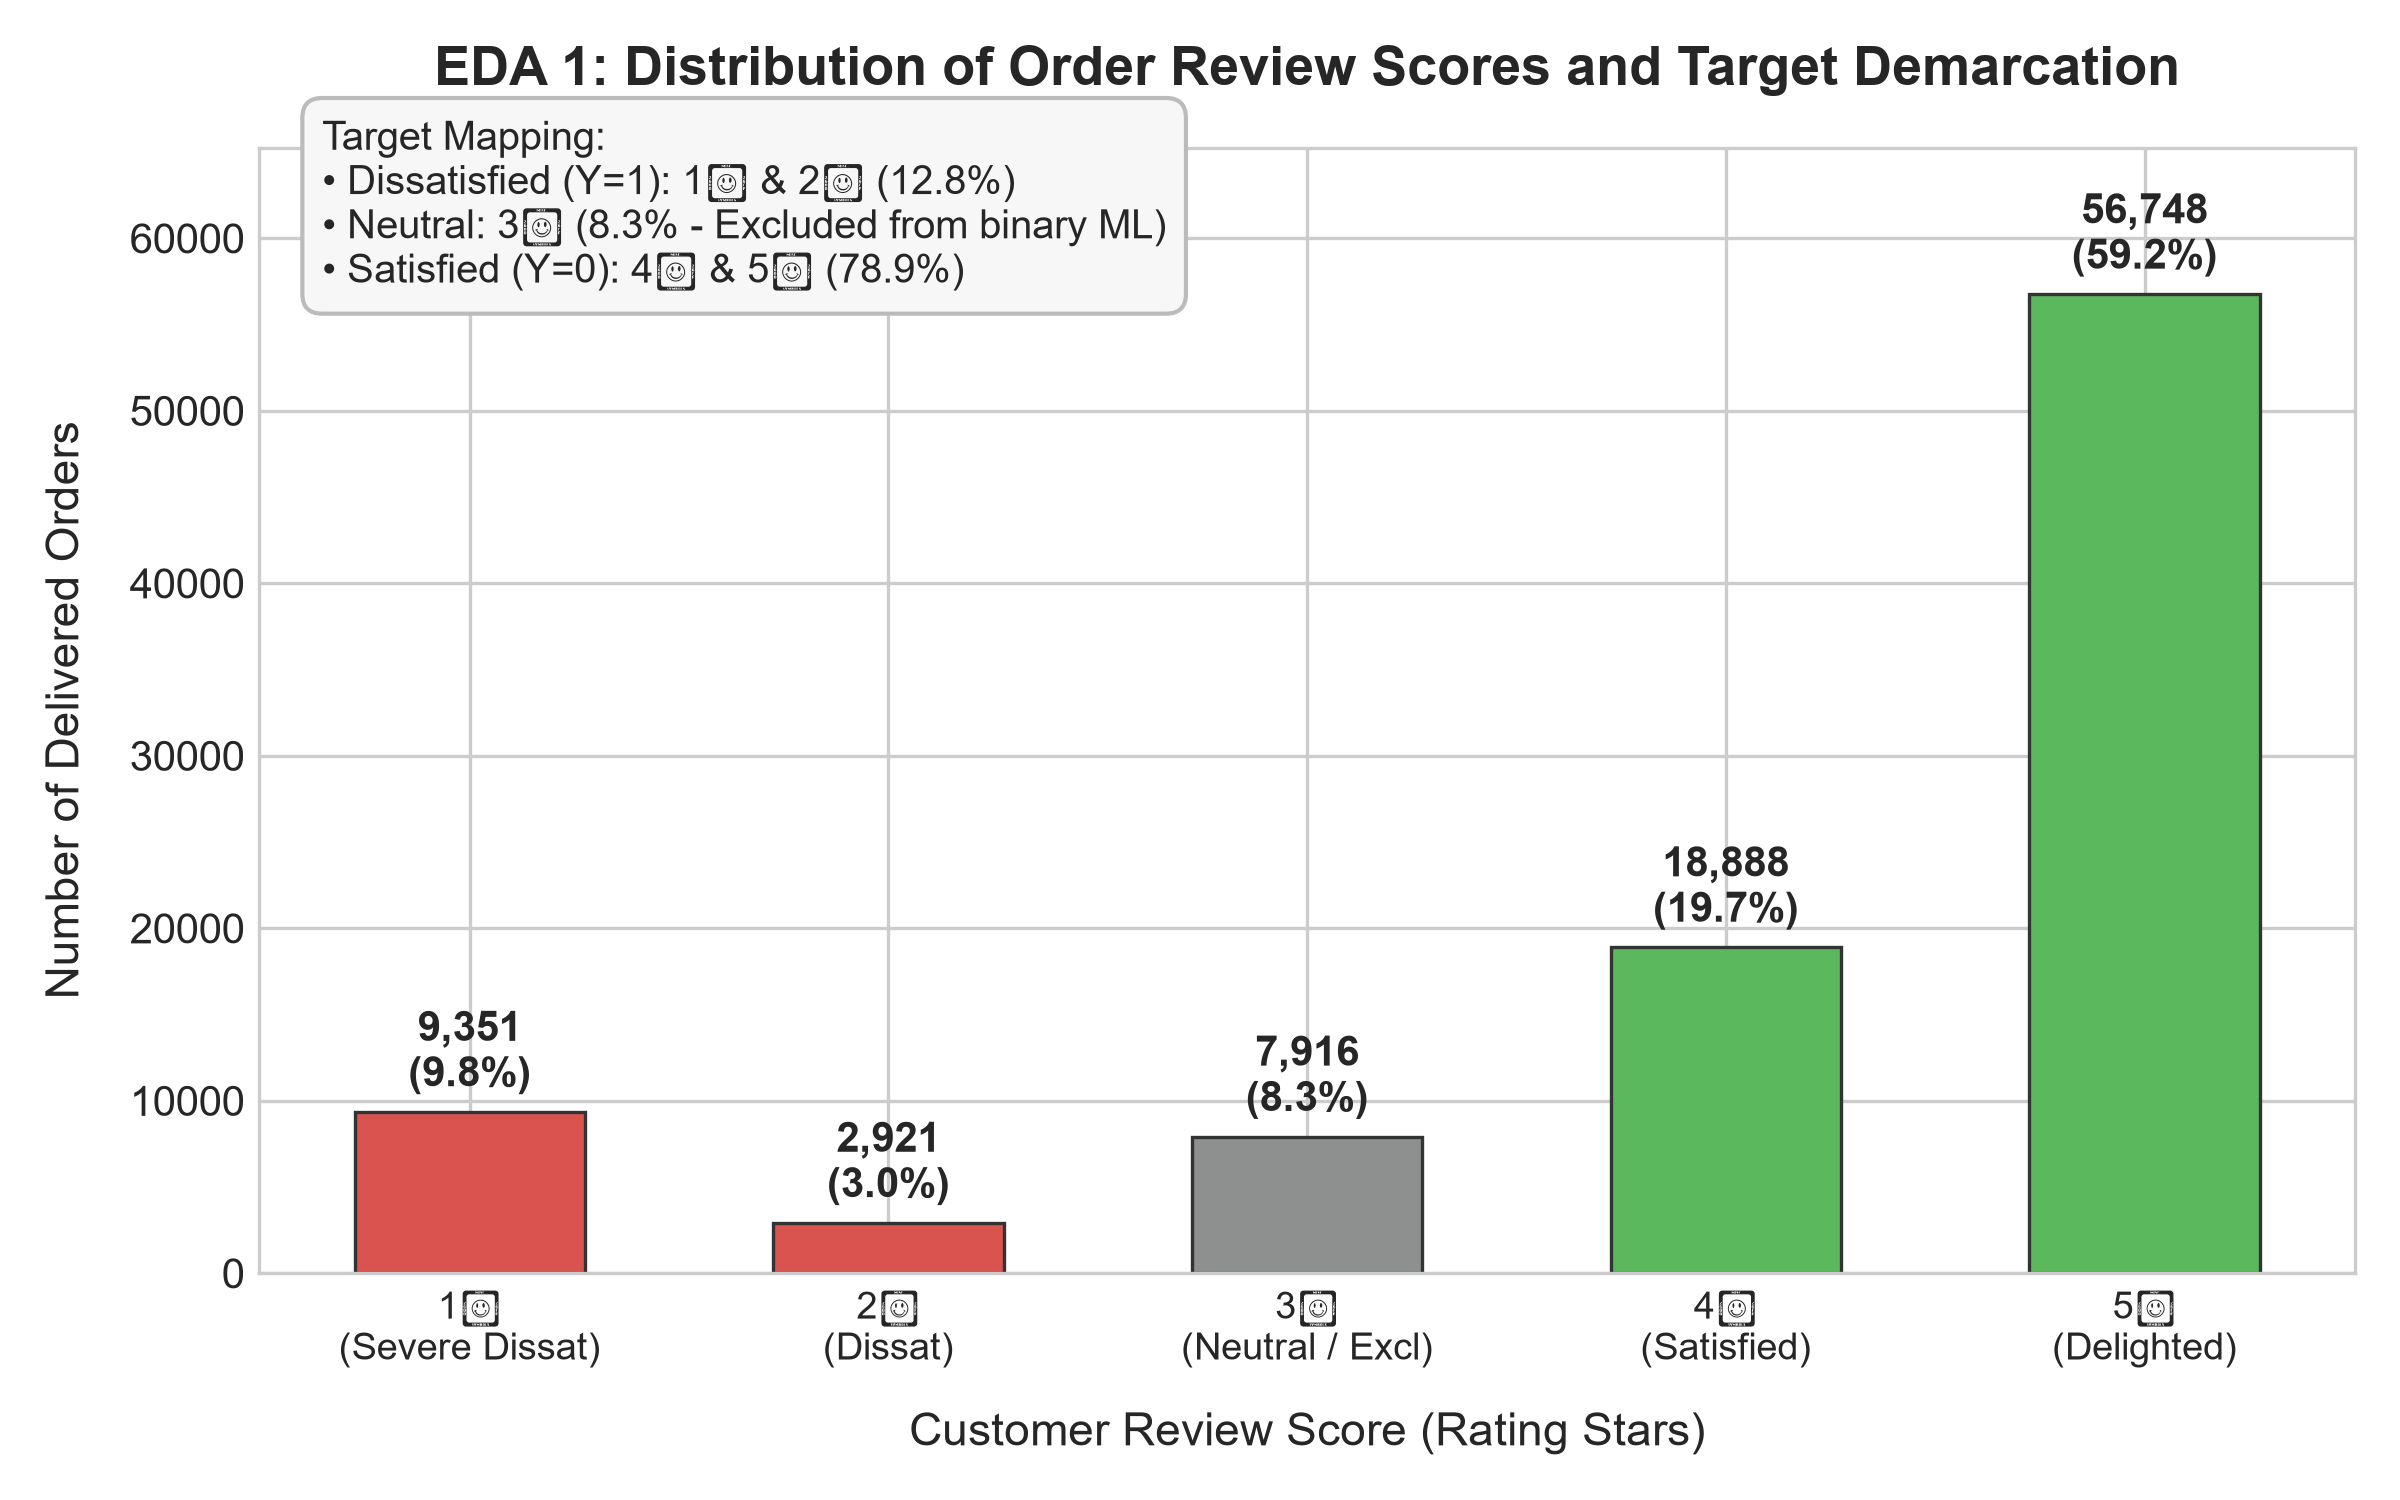

In [7]:
display(Image(filename=os.path.join(FIGURES_DIR, 'eda_1_review_score_distribution.png')))


### EDA 2: Delivery SLA Breach vs Customer Dissatisfaction
Demonstrates the dramatic 5.86x jump in dissatisfaction when orders miss promised delivery dates.


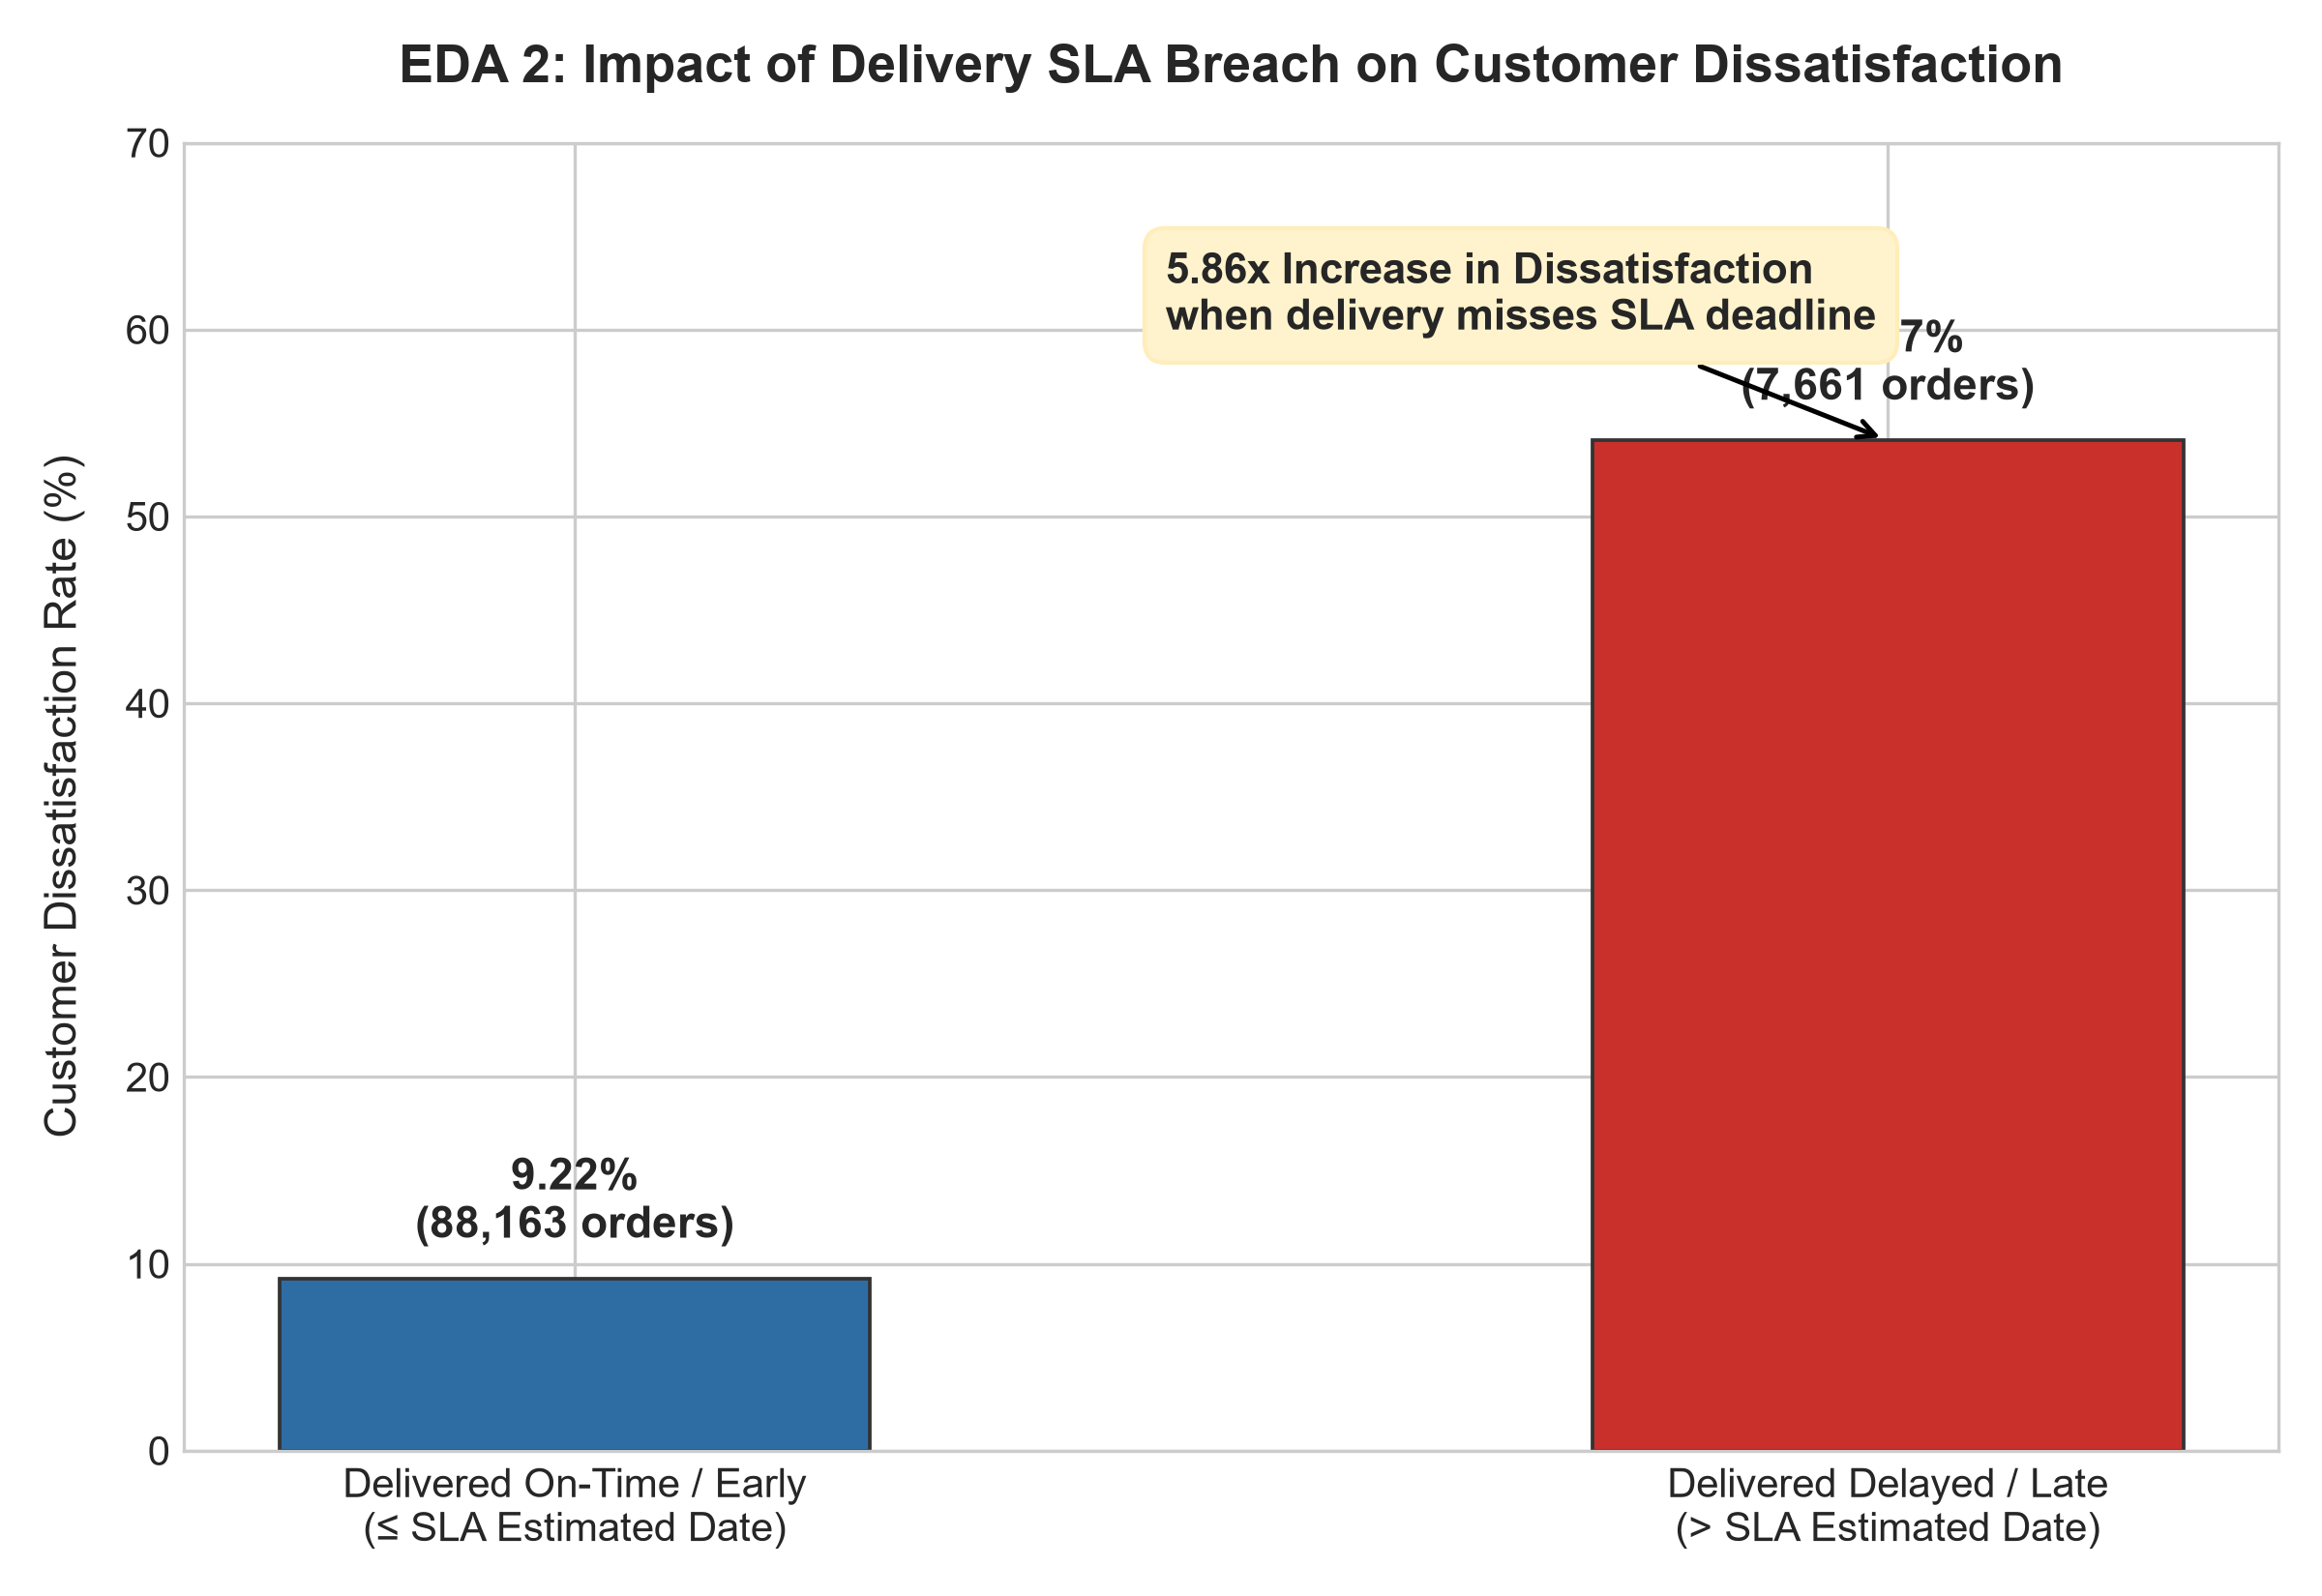

In [8]:
display(Image(filename=os.path.join(FIGURES_DIR, 'eda_2_dissatisfaction_by_delivery_performance.png')))


### EDA 3: Product Category Disparity
Compares dissatisfaction rates across the top 15 product categories by volume.


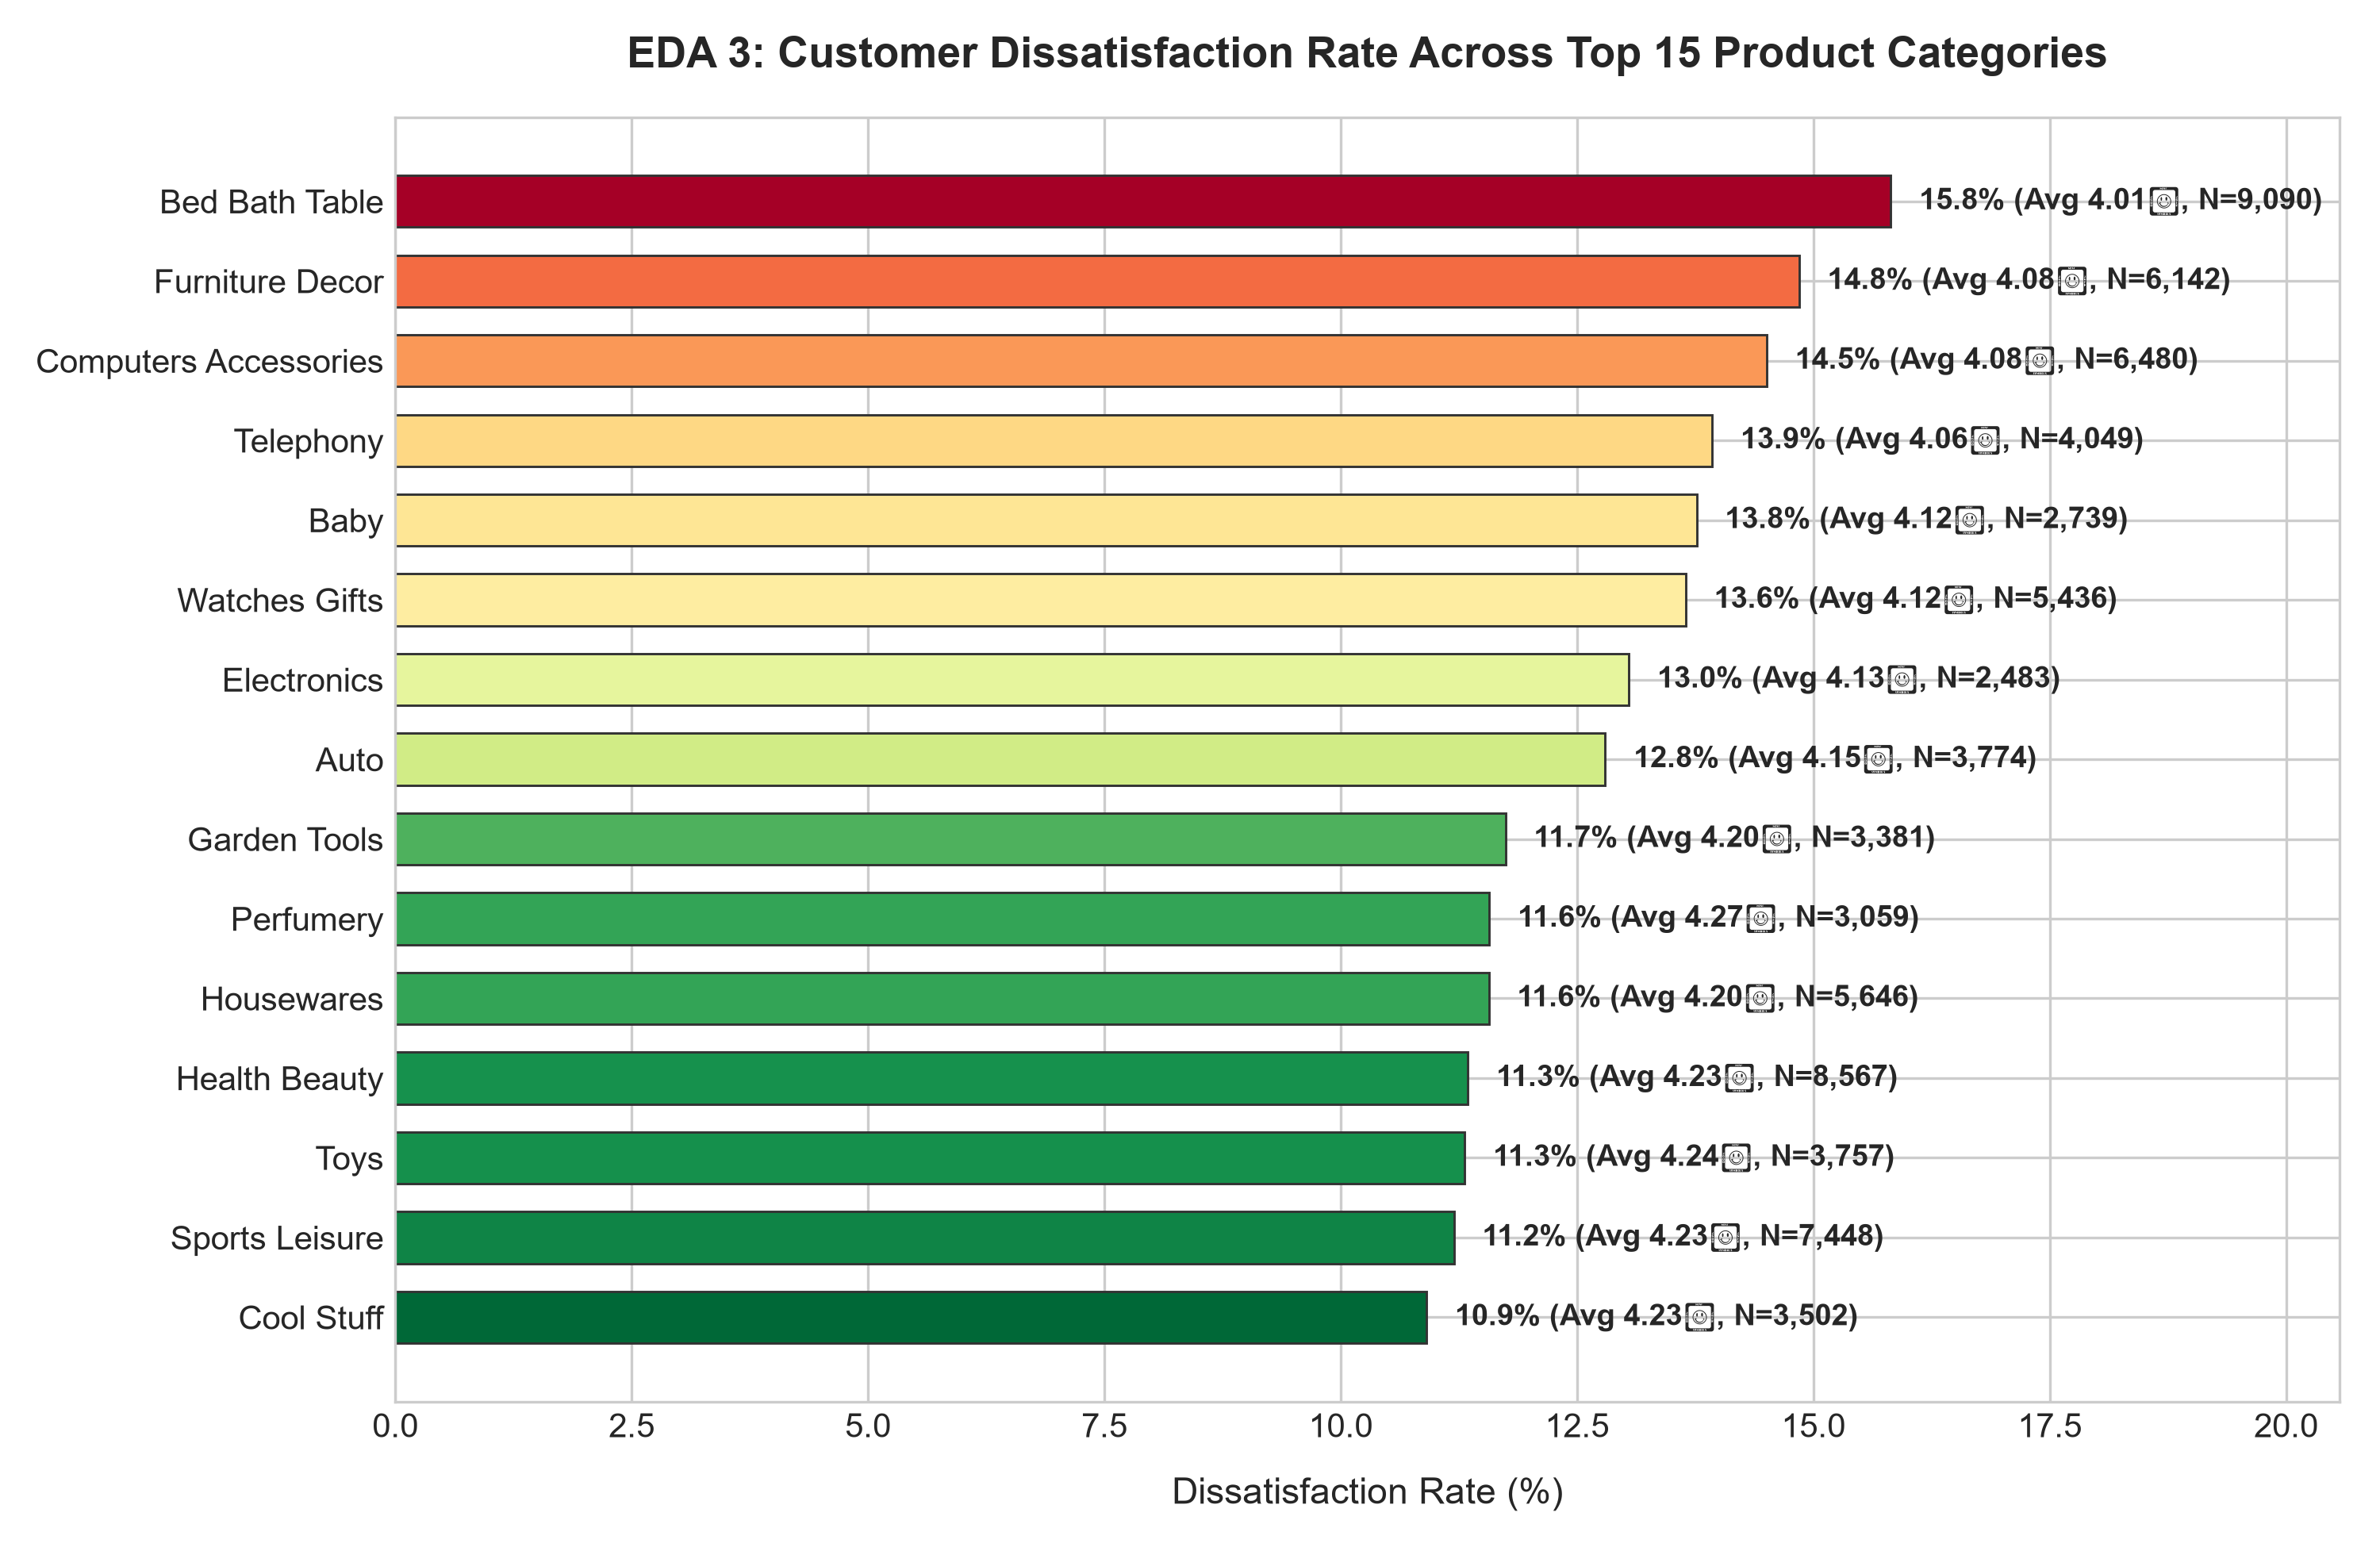

In [9]:
display(Image(filename=os.path.join(FIGURES_DIR, 'eda_3_product_category_dissatisfaction.png')))


### EDA 4: Financial Friction vs Customer Satisfaction
Boxplot comparison of Freight Ratio and Total Order Value between satisfied and dissatisfied customers.


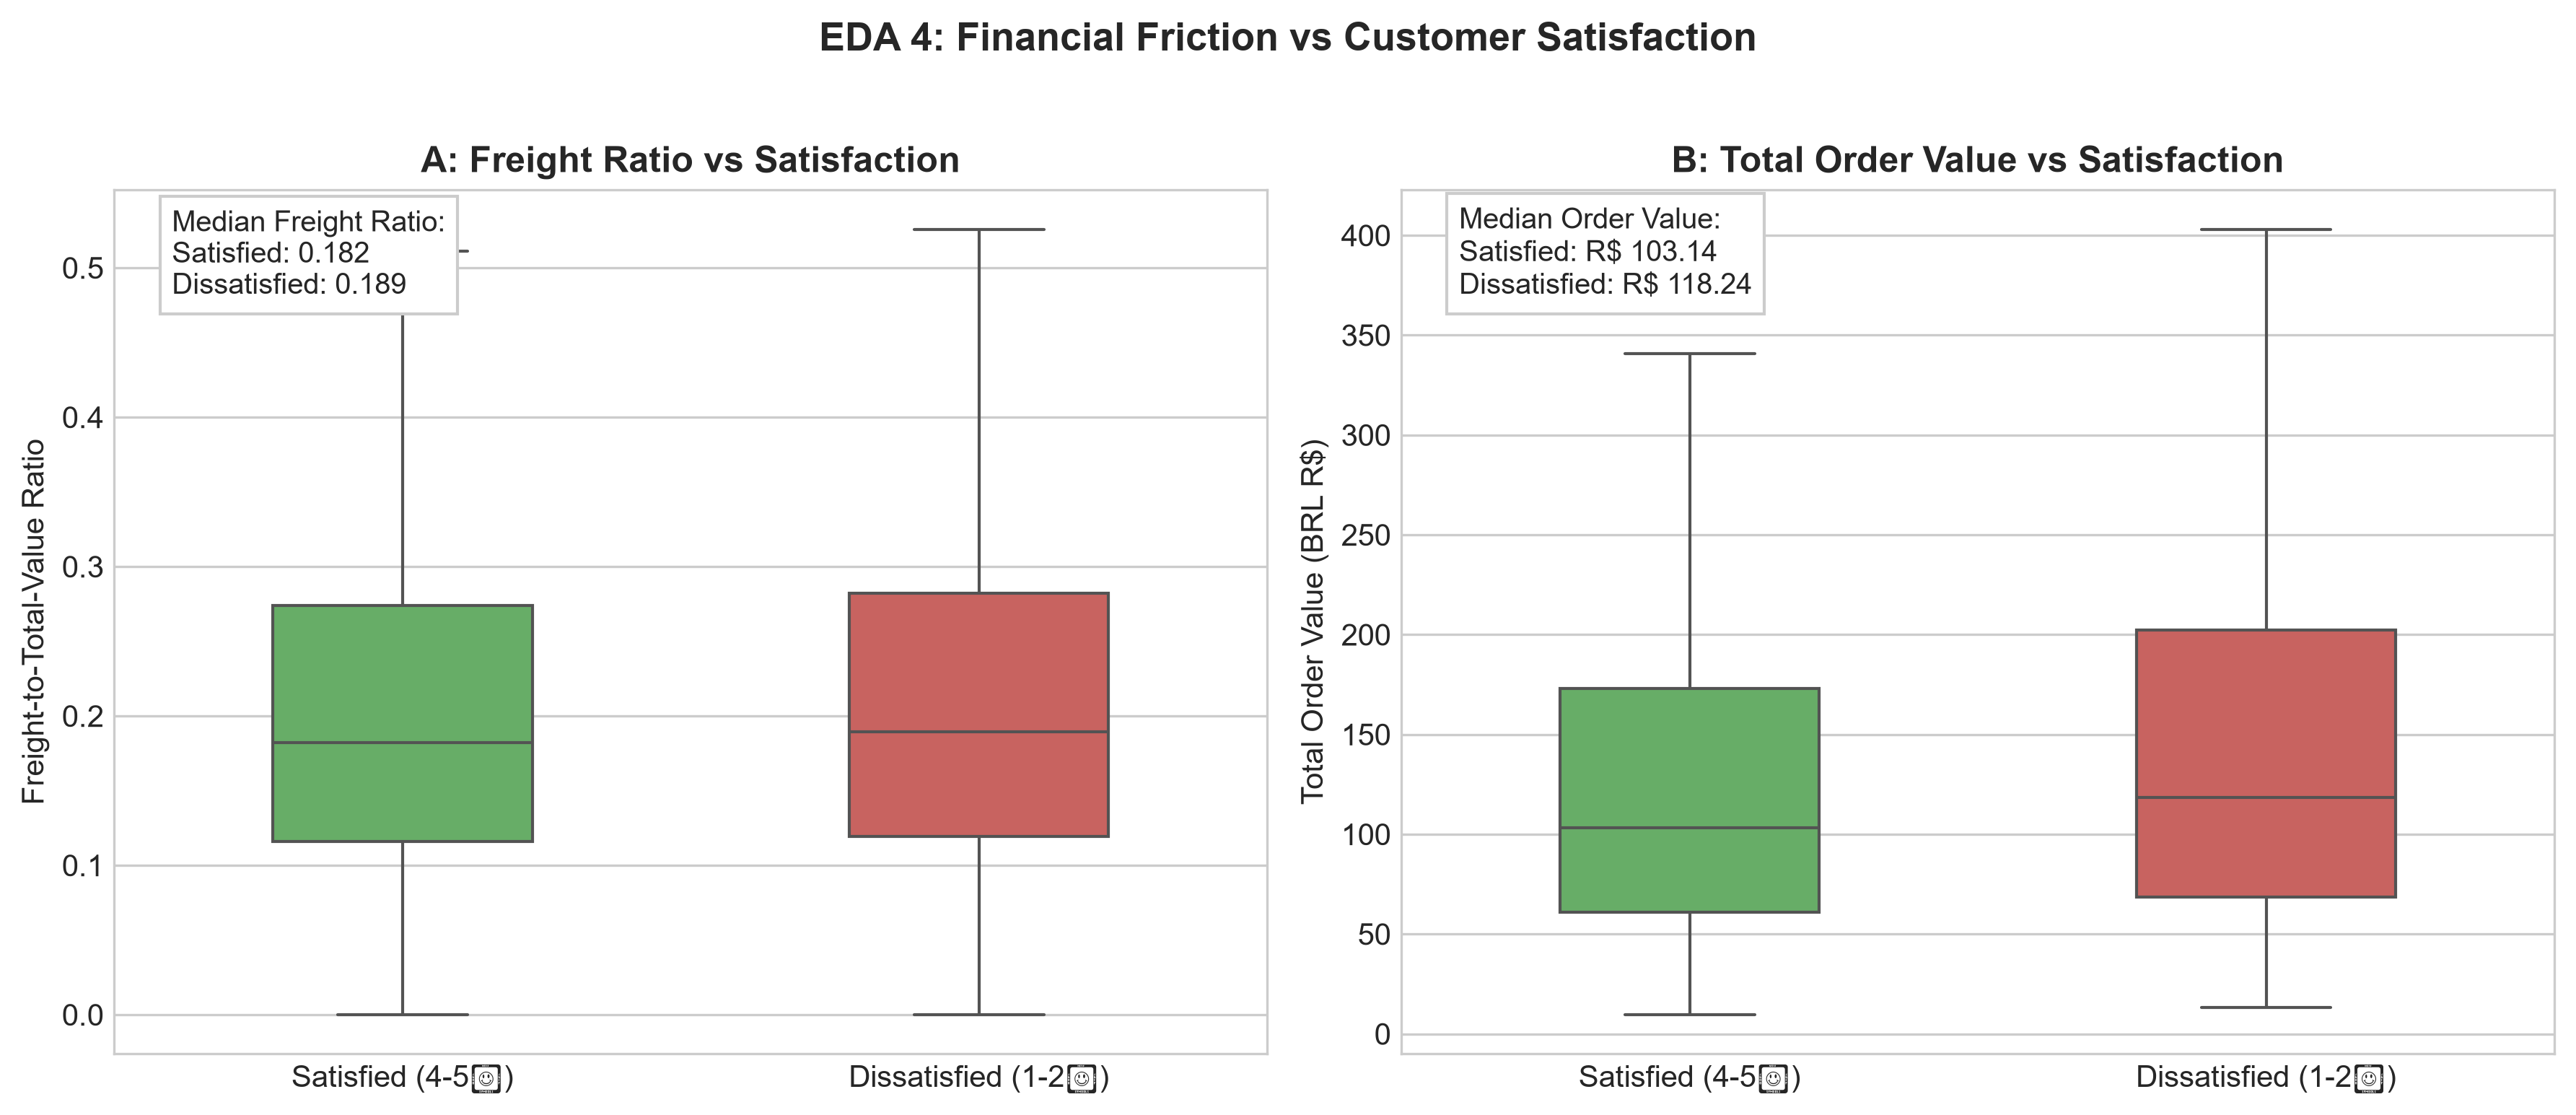

In [10]:
display(Image(filename=os.path.join(FIGURES_DIR, 'eda_4_freight_and_order_value_vs_satisfaction.png')))


### EDA 5: Delivery Delay Distribution
KDE and histogram distribution of delivery delays relative to SLA estimates.


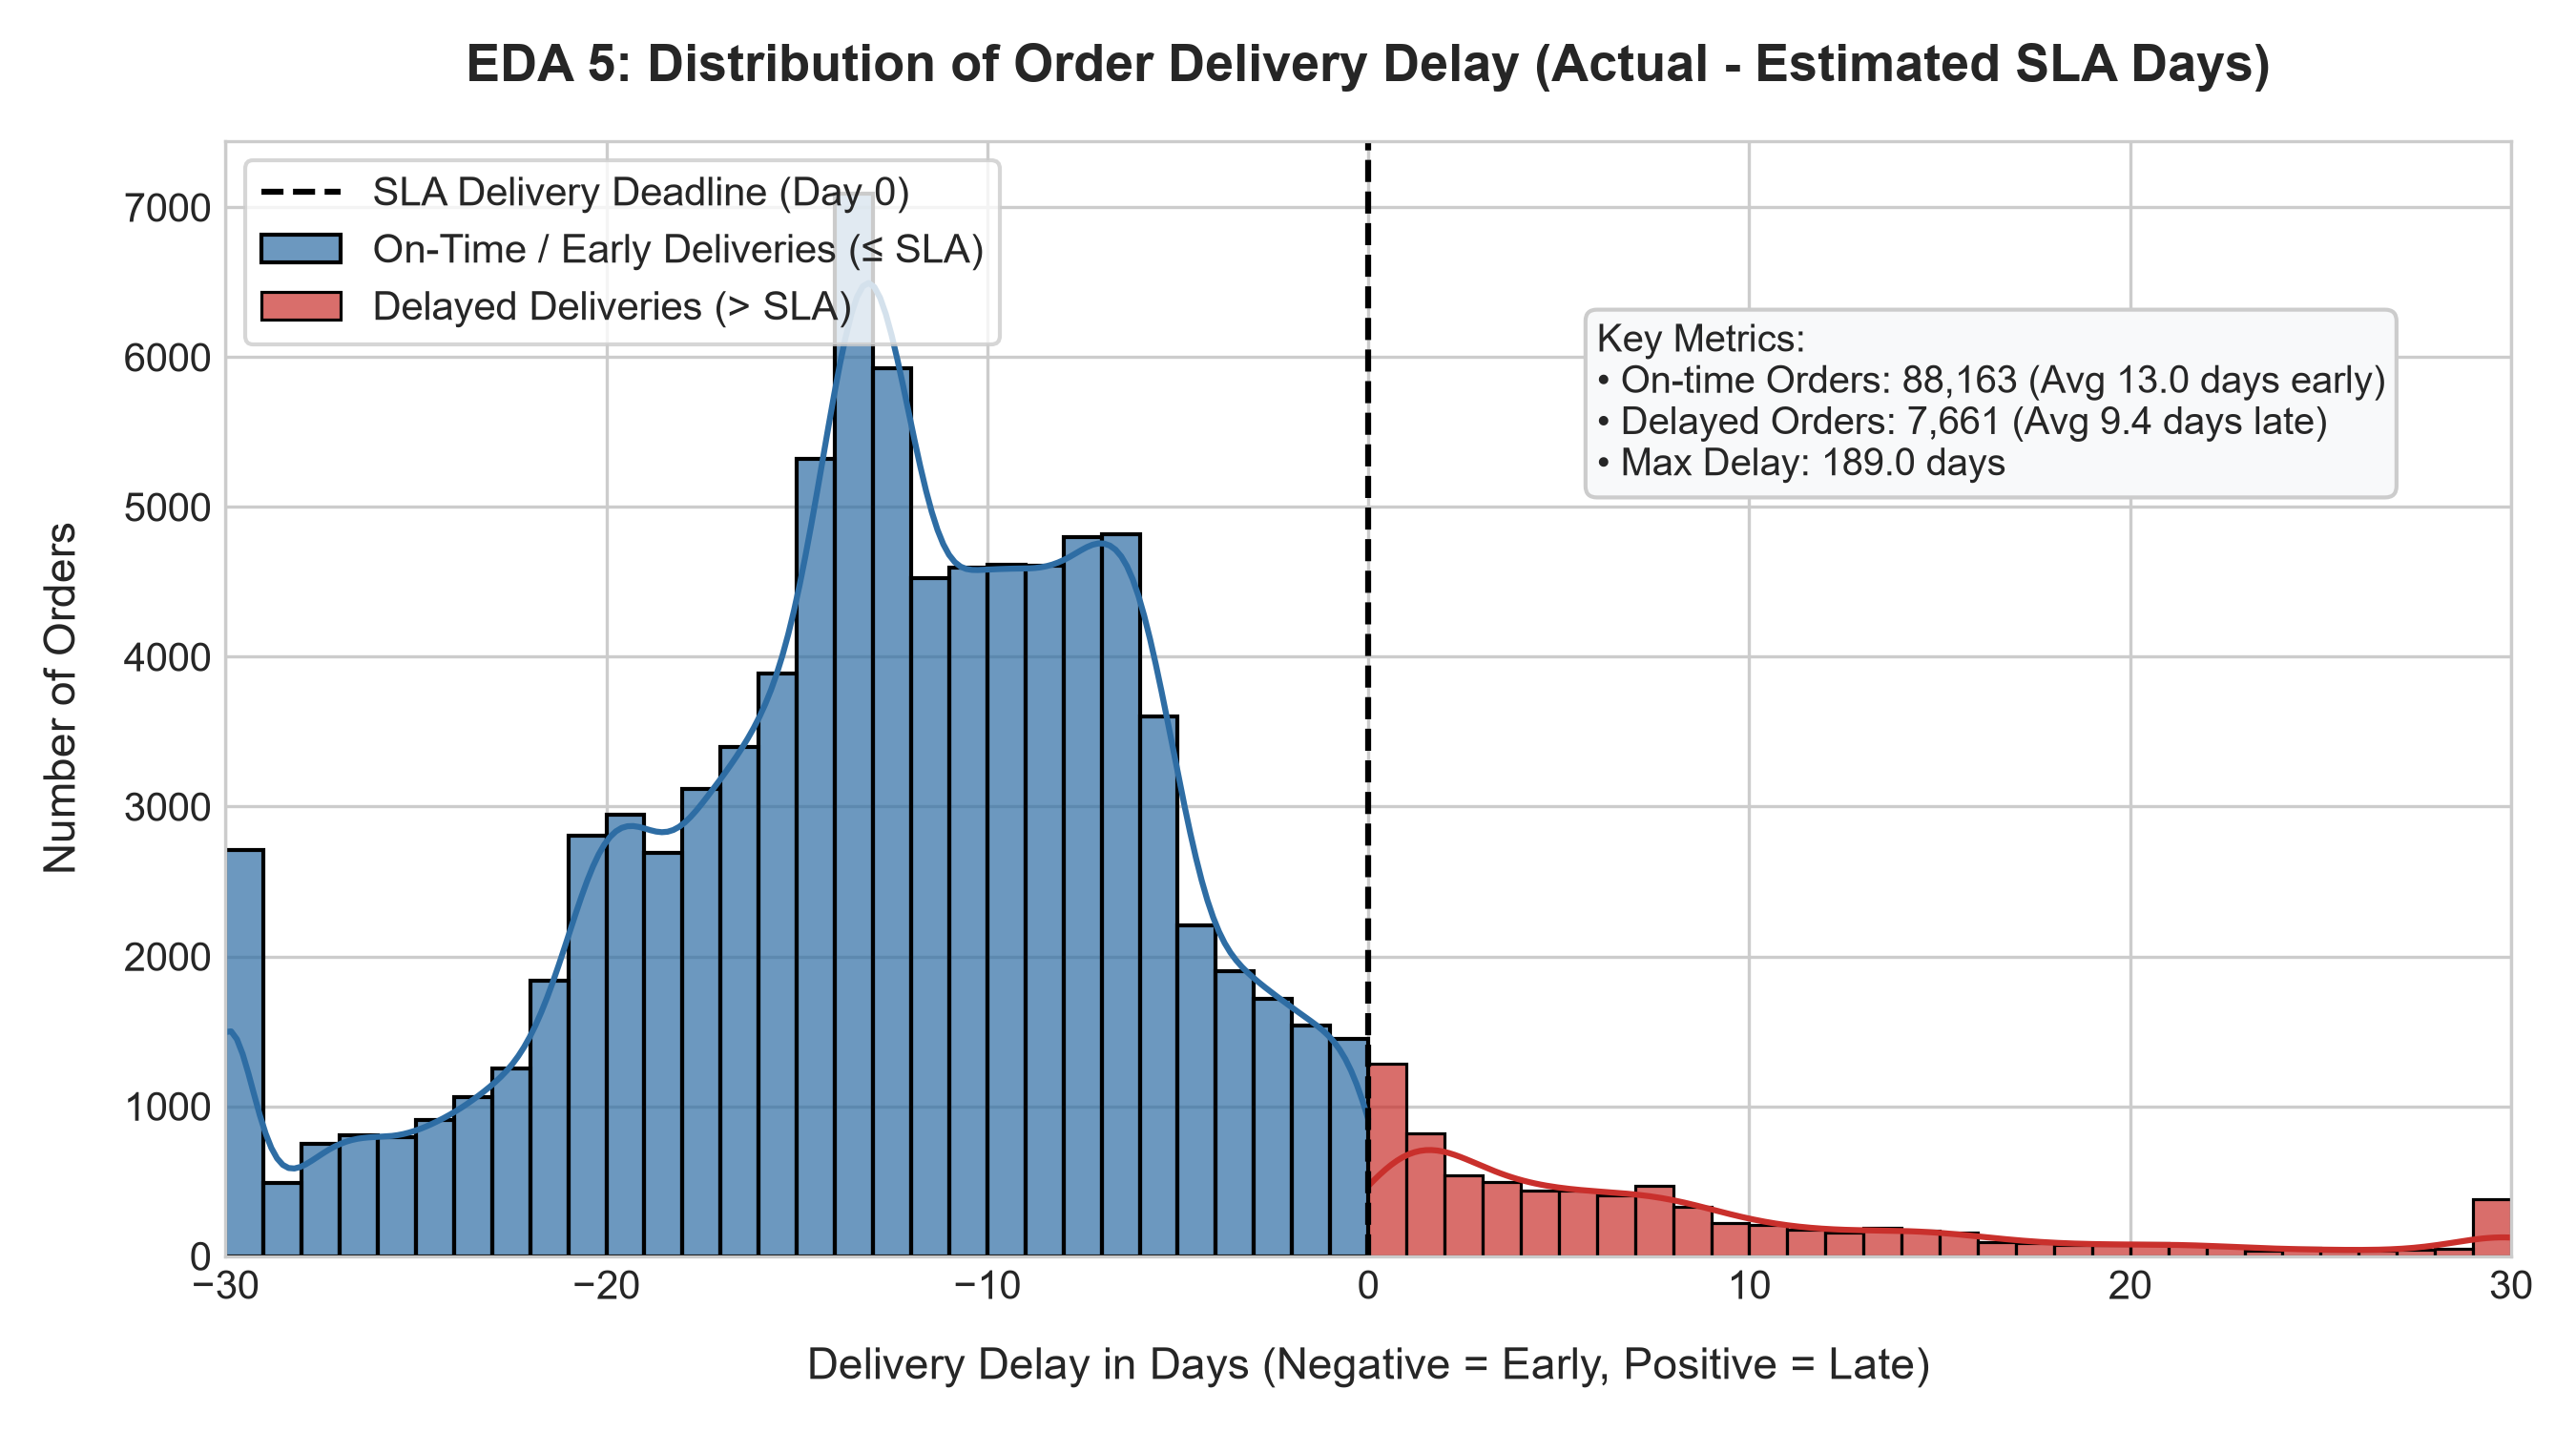

In [11]:
display(Image(filename=os.path.join(FIGURES_DIR, 'eda_5_delivery_delay_distribution.png')))


### EDA 6: Payment Configuration vs Satisfaction
Dissatisfaction across payment methods and installment tiers.


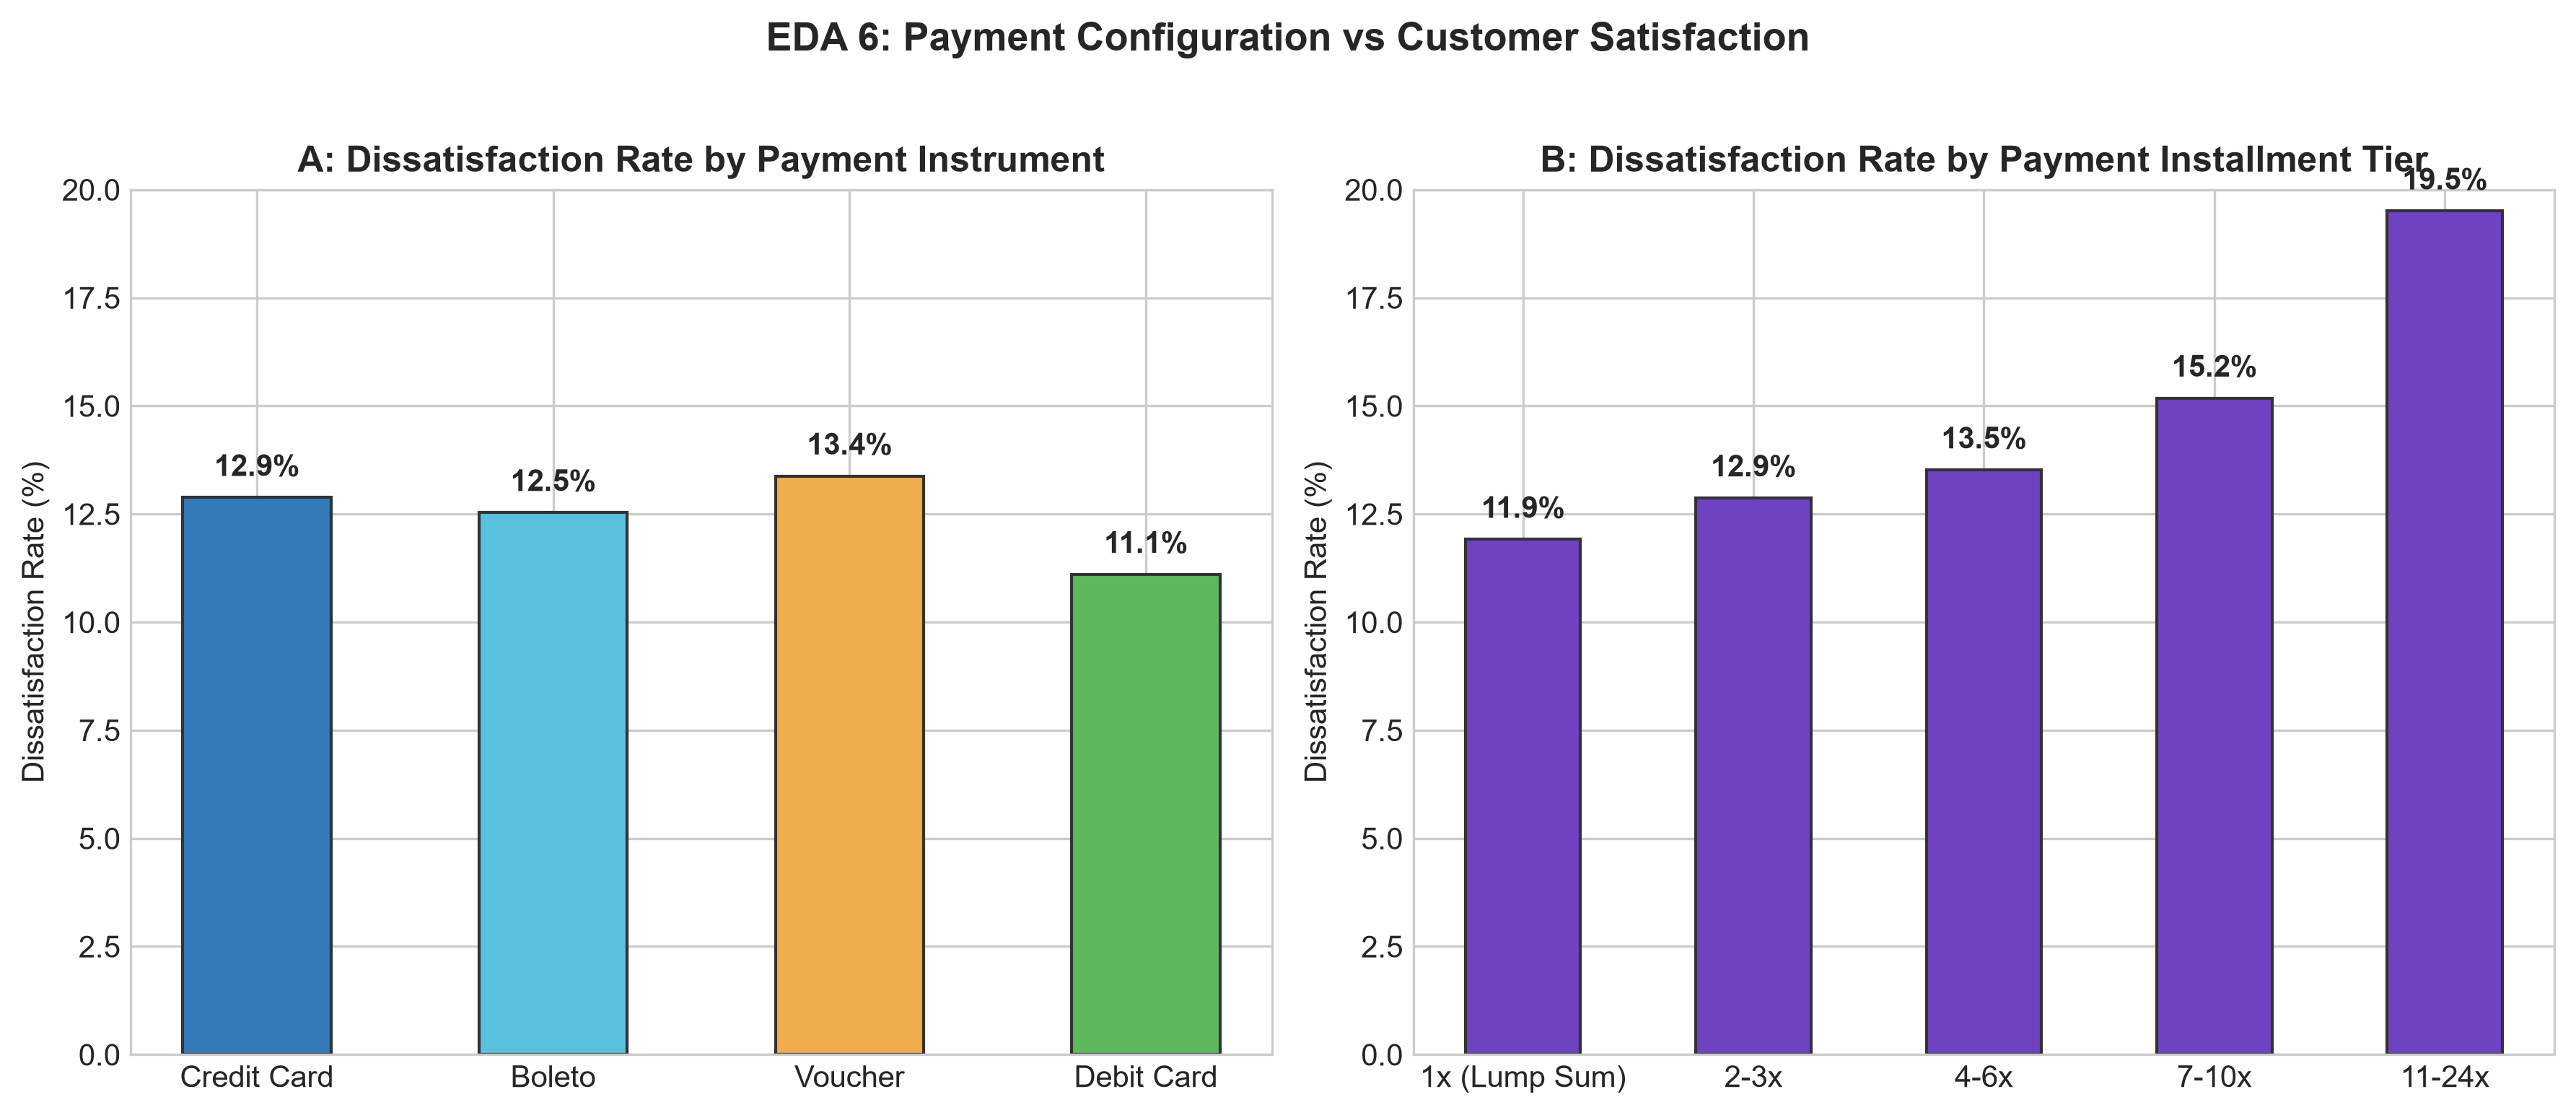

In [12]:
display(Image(filename=os.path.join(FIGURES_DIR, 'eda_6_payment_patterns_vs_satisfaction.png')))


## 7. Synthesis of Empirical Findings & Viva Takeaways


In [13]:
eda_insights = pd.read_csv(os.path.join(TABLES_DIR, 'eda_insights.csv'))
display(eda_insights)


,Analysis Item,Key Metric,Statistical Finding,Actionable Insight
0,Review Score Distribution,"Total Delivered Orders: 95,824","Score 1: 9,351 (9.8%), Score 2: 2,921 (3.0%), ...","Binary target has 12,272 dissatisfied orders (..."
1,Delivery Performance vs Dissatisfaction,On-time Dissat: 9.22% | Delayed Dissat: 54.07%,"Out of 95,824 orders, 7,661 (7.99%) arrived la...",Delivery delay relative to estimated SLA is th...
2,Product Category Disparity,Highest: bed_bath_table (15.8%) | Lowest: cool...,Categories involving bulky furniture or comple...,High-friction categories require specialized c...
3,Financial Friction (Freight Ratio & Value),Median Freight Ratio: Dissatisfied (0.189) vs ...,Dissatisfied customers bear a higher median fr...,High freight charges amplify customer sensitiv...
4,Order Delivery Delay Distribution,Mean Days Early: 13.0 days | Mean Days Late: 9...,92.0% of orders are delivered early (on averag...,Olist sets conservative delivery estimates; wh...
5,Payment Configurations,Boleto Dissat: 12.5% | Credit Card: 12.9% | Mu...,Orders with high installment counts (11-24x) a...,High-installment transactions correspond to hi...


### Key Methodological Conclusions for Academic Defense
1. **Target Leakage Strict Avoidance**: Features derived post-review (ratings, review comments, survey timestamps) are strictly quarantined from the ML feature matrix. All predictive features reflect operational fulfillment state at delivery time.
2. **Class Imbalance Readiness**: Dissatisfaction is observed in 13.96% of the binary classification sample ($12,272$ vs $75,636$). Conventional accuracy is an inappropriate metric; Task 3 must prioritize PR-AUC, F1-Score, and Precision-Recall trade-offs.
3. **Logistics as the Primary Friction Channel**: Delivery delay relative to estimated SLA exhibits the highest individual feature correlation ($r = +0.3927$). Late delivery increases the odds of customer dissatisfaction by nearly six-fold.
